In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import RandomizedSearchCV,GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import precision_score,recall_score,f1_score
from sklearn.metrics import RocCurveDisplay,ConfusionMatrixDisplay
import seaborn as sns
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv('heart-disease.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [4]:
df['sex'].value_counts()

sex
1    207
0     96
Name: count, dtype: int64

In [5]:
pd.crosstab(df.target,df.sex)

sex,0,1
target,,
0,24,114
1,72,93


In [6]:
72/96

0.75

<Axes: xlabel='target'>

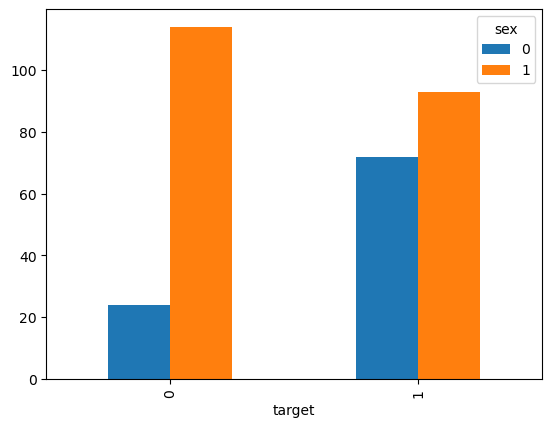

In [7]:
pd.crosstab(df.target,df.sex).plot(kind = 'bar')

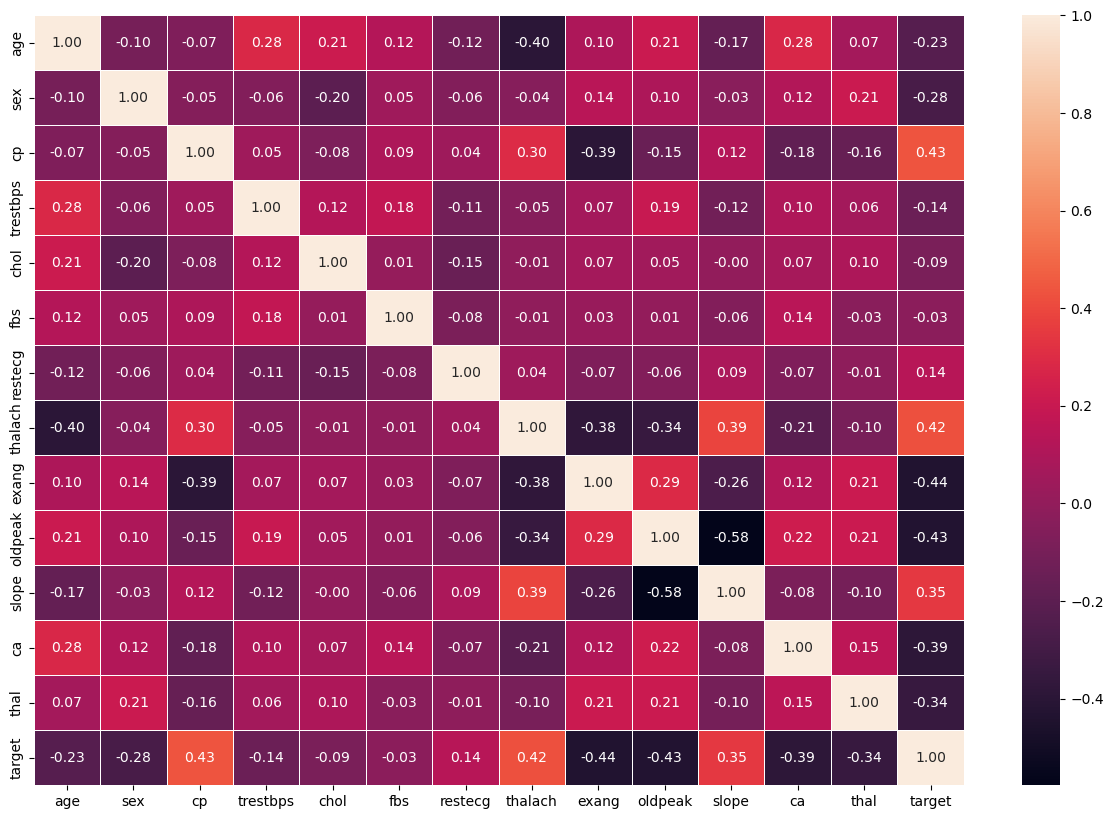

In [8]:
corr_matrix = df.corr()
fig,ax = plt.subplots(figsize = (15,10))
ax = sns.heatmap(corr_matrix,annot = True,
                linewidths=0.5,
                fmt = '.2f')

In [9]:
x = df.drop('target',axis =1)
y = df.target

In [10]:
x

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3


In [11]:
y

0      1
1      1
2      1
3      1
4      1
      ..
298    0
299    0
300    0
301    0
302    0
Name: target, Length: 303, dtype: int64

In [12]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2)

In [13]:
# Put models in a dictionary
models = {"Logistic Regression": LogisticRegression(),
          "KNN": KNeighborsClassifier(),
          "Random Forest": RandomForestClassifier()}

# Create a function to fit and score models
def fit_and_score(models, x_train, x_test, y_train, y_test):
    """
    Fits and evaluates given machine learning models.
    models : a dict of differetn Scikit-Learn machine learning models
    X_train : training data (no labels)
    X_test : testing data (no labels)
    y_train : training labels
    y_test : test labels
    """
    # Set random seed
    np.random.seed(42)
    # Make a dictionary to keep model scores
    model_scores = {}
    # Loop through models
    for name, model in models.items():
        # Fit the model to the data
        model.fit(x_train, y_train)
        # Evaluate the model and append its score to model_scores
        model_scores[name] = model.score(x_test, y_test)
    return model_scores

In [14]:
scores = fit_and_score(models,x_train,x_test,y_train,y_test)
scores

C:\Users\kakha\OneDrive\Desktop\heart-disease\env\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'Logistic Regression': 0.9180327868852459,
 'KNN': 0.5737704918032787,
 'Random Forest': 0.9016393442622951}

<Axes: >

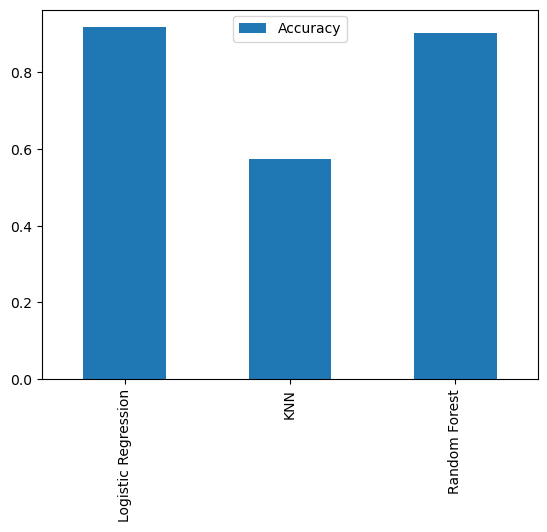

In [15]:
compare = pd.DataFrame(scores,index = ['Accuracy'])
compare.T.plot.bar()

In [19]:
train_scores=[]
test_scores = []
neighbors = range(1,21)
knn = KNeighborsClassifier()

for i in neighbors:
    knn.set_params(n_neighbors=i)
    knn.fit(x_train,y_train)
    train_scores.append(knn.score(x_train,y_train))
    test_scores.append(knn.score(x_test,y_test))

In [20]:
train_scores

[1.0,
 0.8305785123966942,
 0.8099173553719008,
 0.7727272727272727,
 0.78099173553719,
 0.756198347107438,
 0.7479338842975206,
 0.7355371900826446,
 0.7231404958677686,
 0.7148760330578512,
 0.7355371900826446,
 0.7107438016528925,
 0.7024793388429752,
 0.7066115702479339,
 0.7024793388429752,
 0.7148760330578512,
 0.7355371900826446,
 0.7272727272727273,
 0.71900826446281,
 0.7231404958677686]

In [21]:
test_scores

[0.4262295081967213,
 0.45901639344262296,
 0.5081967213114754,
 0.47540983606557374,
 0.5737704918032787,
 0.5901639344262295,
 0.5901639344262295,
 0.5573770491803278,
 0.5901639344262295,
 0.6065573770491803,
 0.6229508196721312,
 0.6065573770491803,
 0.5573770491803278,
 0.5901639344262295,
 0.5409836065573771,
 0.5409836065573771,
 0.5245901639344263,
 0.5409836065573771,
 0.5245901639344263,
 0.5245901639344263]

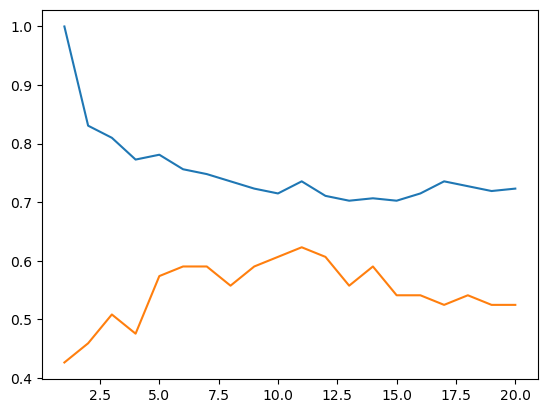

In [22]:
plt.plot(neighbors,train_scores)
plt.plot(neighbors,test_scores)

In [25]:
print(f'maximum KNN score on test data is :{max(test_scores)*100:.2f}%')

maximum KNN score on test data is :62.30%


In [35]:
log_reg_grid = {'C':np.logspace(-4,4,20),
               'solver':['liblinear']}

rf_grid = {'n_estimators':np.arange(10,1000,50),
          'max_depth':[None,3,5,10],
          'min_samples_split':np.arange(2,20,2),
          'min_samples_leaf':np.arange(1,20,2)}

In [28]:
np.random.seed(42)

rs_log_reg = RandomizedSearchCV(LogisticRegression(),param_distributions=log_reg_grid,cv = 5,verbose =2)
rs_log_reg.fit(x_train,y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END .........................C=0.0001, solver=liblinear; total time=   0.0s
[CV] END ...............C=1438.44988828766, solver=liblinear; total time=   0.0s
[CV] END ...............C=1438.44988828766, solver=liblinear; total time=   0.0s
[CV] END ...............C=1438.44988828766, solver=liblinear; total time=   0.0s
[CV] END ...............C=1438.44988828766, solver=liblinear; total time=   0.0s
[CV] END ...............C=1438.44988828766, solver=liblinear; total time=   0.0s
[CV] END ...............C=206.913808111479, solver=liblinear; total time=   0.0s
[CV] END ...............C=206.913808111479, solv

RandomizedSearchCV(cv=5, estimator=LogisticRegression(),
                   param_distributions={'C': array([1.00000000e-04, 2.63665090e-04, 6.95192796e-04, 1.83298071e-03,
       4.83293024e-03, 1.27427499e-02, 3.35981829e-02, 8.85866790e-02,
       2.33572147e-01, 6.15848211e-01, 1.62377674e+00, 4.28133240e+00,
       1.12883789e+01, 2.97635144e+01, 7.84759970e+01, 2.06913808e+02,
       5.45559478e+02, 1.43844989e+03, 3.79269019e+03, 1.00000000e+04]),
                                        'solver': ['liblinear']},
                   verbose=2)

In [29]:
rs_log_reg.best_params_

{'solver': 'liblinear', 'C': 0.23357214690901212}

In [30]:
rs_log_reg.score(x_test,y_test)

0.9016393442622951

In [36]:
rs_rf = RandomizedSearchCV(RandomForestClassifier(),param_distributions=rf_grid,
                          cv=5,verbose = 2)
rs_rf.fit(x_train,y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END max_depth=None, min_samples_leaf=17, min_samples_split=16, n_estimators=260; total time=   0.3s
[CV] END max_depth=None, min_samples_leaf=17, min_samples_split=16, n_estimators=260; total time=   0.2s
[CV] END max_depth=None, min_samples_leaf=17, min_samples_split=16, n_estimators=260; total time=   0.2s
[CV] END max_depth=None, min_samples_leaf=17, min_samples_split=16, n_estimators=260; total time=   0.1s
[CV] END max_depth=None, min_samples_leaf=17, min_samples_split=16, n_estimators=260; total time=   0.1s
[CV] END max_depth=5, min_samples_leaf=3, min_samples_split=18, n_estimators=160; total time=   0.0s
[CV] END max_depth=5, min_samples_leaf=3, min_samples_split=18, n_estimators=160; total time=   0.0s
[CV] END max_depth=5, min_samples_leaf=3, min_samples_split=18, n_estimators=160; total time=   0.0s
[CV] END max_depth=5, min_samples_leaf=3, min_samples_split=18, n_estimators=160; total time=   0.0s
[CV] END m

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(),
                   param_distributions={'max_depth': [None, 3, 5, 10],
                                        'min_samples_leaf': array([ 1,  3,  5,  7,  9, 11, 13, 15, 17, 19]),
                                        'min_samples_split': array([ 2,  4,  6,  8, 10, 12, 14, 16, 18]),
                                        'n_estimators': array([ 10,  60, 110, 160, 210, 260, 310, 360, 410, 460, 510, 560, 610,
       660, 710, 760, 810, 860, 910, 960])},
                   verbose=2)

In [37]:
rs_rf.score(x_test,y_test)

0.8360655737704918

In [38]:
rs_rf.best_params_

{'n_estimators': 10,
 'min_samples_split': 8,
 'min_samples_leaf': 17,
 'max_depth': None}

In [40]:
scores

{'Logistic Regression': 0.9180327868852459,
 'KNN': 0.5737704918032787,
 'Random Forest': 0.9016393442622951}